<a href="https://colab.research.google.com/github/Kushagra14/triton_tutorials/blob/main/Triton_Fused_softmax.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install triton

In [2]:
import torch

import triton
import triton.language as tl
from triton.runtime import driver

DEVICE = triton.runtime.driver.active.get_active_torch_device()


def is_hip():
    return triton.runtime.driver.active.get_current_target().backend == "hip"


def is_cdna():
    return is_hip() and triton.runtime.driver.active.get_current_target().arch in ('gfx940', 'gfx941', 'gfx942',
                                                                                   'gfx90a')


def naive_softmax(x):
    """Compute row-wise softmax of X using native pytorch

    We subtract the maximum element in order to avoid overflows. Softmax is invariant to
    this shift.
    """
    # read  MN elements ; write M  elements
    x_max = x.max(dim=1)[0]
    # read MN + M elements ; write MN elements
    z = x - x_max[:, None]
    # read  MN elements ; write MN elements
    numerator = torch.exp(z)
    # read  MN elements ; write M  elements
    denominator = numerator.sum(dim=1)
    # read MN + M elements ; write MN elements
    ret = numerator / denominator[:, None]
    # in total: read 5MN + 2M elements ; wrote 3MN + 2M elements
    return ret

## 🔍 The DRAM Fetch Bottleneck in PyTorch

In standard deep learning frameworks, operations are executed sequentially. Under the hood, this sequential dispatch creates a severe performance bottleneck on memory-bound workloads:

* **Excessive DRAM Fetches**: Each basic operation (like subtract, exponentiate, or sum) must read its inputs from Global Memory (DRAM) and write its intermediate outputs back to DRAM.
* **Memory-Bound Bottleneck**: Mathematical operations like addition, division, and exponentiation require very few compute cycles relative to the number of bytes they fetch. The GPU spending its power waiting on memory channels is known as being **memory-bandwidth bound**.

Merging these steps into a single unified execution context (fusing them) allows us to reuse data directly from the high-speed on-chip memory (registers/SRAM) without unnecessary DRAM roundtrips.

### Detailed Explanation: Naive vs. Fused (Triton) Softmax Bottlenecks

In standard deep learning frameworks like PyTorch, operations are executed sequentially. Each individual operation in your `naive_softmax` function creates intermediate tensors and forces data to travel back and forth between the high-bandwidth on-chip memory (SRAM) and the off-chip memory (DRAM).

Here is a breakdown of why this is highly inefficient for memory-bound tasks:

#### 1. The DRAM Bandwidth Bottleneck
GPUs have massive computational power (ALUs) but are severely limited by the time it takes to fetch data from and write data to the global memory (DRAM).
* **Memory-bound Operations**: Operations like addition, exponential, division, and summation require very few calculations per byte of data loaded. Thus, the GPU spent most of its time waiting for DRAM memory transfers rather than performing actual mathematical computations.

#### 2. Naive PyTorch Step-by-Step Memory Access Analysis
Let's map out exactly how the elements of an $M \times N$ matrix are read from and written to DRAM in your `naive_softmax` implementation:

1. `x_max = x.max(dim=1)[0]`
   * **Reads**: $M \times N$ elements from DRAM (to compute the maximum of each row).
   * **Writes**: $M$ elements to DRAM (the maximum values for each row).
2. `z = x - x_max[:, None]`
   * **Reads**: $M \times N$ elements ($x$) + $M$ elements ($x\_max$) from DRAM.
   * **Writes**: $M \times N$ elements ($z$) to DRAM.
3. `numerator = torch.exp(z)`
   * **Reads**: $M \times N$ elements from DRAM.
   * **Writes**: $M \times N$ elements to DRAM.
4. `denominator = numerator.sum(dim=1)`
   * **Reads**: $M \times N$ elements from DRAM.
   * **Writes**: $M$ elements to DRAM.
5. `ret = numerator / denominator[:, None]`
   * **Reads**: $M \times N$ elements (`numerator`) + $M$ elements (`denominator`) from DRAM.
   * **Writes**: $M \times N$ elements (`ret`) to DRAM.

**Total DRAM Traffic:**
* **Total Reads**: $5MN + 2M$ elements
* **Total Writes**: $3MN + 2M$ elements

#### 3. How Triton's Fused Kernel Solves This
Triton allows us to write custom GPU kernels where we control memory transfers at a thread-block level. Instead of executing sequentially and round-tripping to DRAM, we **fuse** all operations into a single kernel execution:

1. **Single Read**: A GPU thread block loads an entire row ($N$ elements) from DRAM straight into the GPU's high-speed **SRAM (Registers)**.
2. **In-Register Computation**: The maximum calculation, subtraction, exponentiation, sum, and division are all computed entirely inside the SRAM registers. No intermediate matrices ($z$, `numerator`, etc.) are ever written back to DRAM.
3. **Single Write**: The final computed softmax values ($N$ elements) are written from SRAM back to DRAM once.

**Total Fused DRAM Traffic:**
* **Total Reads**: $M \times N$ elements (each element is read exactly once)
* **Total Writes**: $M \times N$ elements (only the final results are written back)

#### Summary Comparison

| Metric | Naive PyTorch Implementation | Fused Triton Kernel |
| :--- | :--- | :--- |
| **DRAM Reads** | $5MN + 2M$ elements | **$MN$ elements** (5x reduction) |
| **DRAM Writes** | $3MN + 2M$ elements | **$MN$ elements** (3x reduction) |
| **Performance Limit** | Memory bandwidth bound (DRAM bottlenecked) | Compute bound or SRAM speed bound |
| **Intermediate Storage**| Creates multiple large temporary tensors in GPU memory | Keeps all intermediate results in registers |

In [11]:
@triton.jit
def softmax_kernel(output_ptr, input_ptr, input_row_stride, output_row_stride, n_rows, n_cols, BLOCK_SIZE: tl.constexpr,
                   num_stages: tl.constexpr):
    # starting row of the program
    row_start = tl.program_id(0)
    row_step = tl.num_programs(0)
    for row_idx in tl.range(row_start, n_rows, row_step, num_stages=num_stages):
        # The stride represents how much we need to increase the pointer to advance 1 row
        row_start_ptr = input_ptr + row_idx * input_row_stride
        # The block size is the next power of two greater than n_cols, so we can fit each
        # row in a single block
        col_offsets = tl.arange(0, BLOCK_SIZE)
        input_ptrs = row_start_ptr + col_offsets
        # Load the row into SRAM, using a mask since BLOCK_SIZE may be > than n_cols
        mask = col_offsets < n_cols
        row = tl.load(input_ptrs, mask=mask, other=-float('inf'))
        # Subtract maximum for numerical stability
        row_minus_max = row - tl.max(row, axis=0)
        # Note that exponentiation in Triton is fast but approximate (i.e., think __expf in CUDA)
        numerator = tl.exp(row_minus_max)
        denominator = tl.sum(numerator, axis=0)
        softmax_output = numerator / denominator
        # Write back output to DRAM
        output_row_start_ptr = output_ptr + row_idx * output_row_stride
        output_ptrs = output_row_start_ptr + col_offsets
        tl.store(output_ptrs, softmax_output, mask=mask)

### 🛠️ Hardware-Level Mechanics: `row_step` & `num_stages`

To make our Triton kernel highly robust and efficient, we use two advanced concepts:

1. **Grid-Stride Loops (`row_step = tl.num_programs(0)`)**  
   Instead of launching exactly one GPU thread block per matrix row (which performs poorly for matrices with millions of rows), we use a grid-stride loop pattern. If we launch $K$ programs, program `0` processes row `0`, then jumps to row `0 + K`, then `0 + 2K`, and so on. This handles arbitrary dimensions cleanly and optimizes hardware occupancy.

2. **Software Pipelining (`num_stages`)**  
   This parameter is passed directly to our loop compilation. It directs the Triton compiler to overlap/prefetch memory instructions across loop iterations, letting the GPU load the next block of data from DRAM while simultaneously computing the current step in the registers.

In [12]:
# 1. Helper Launcher for the Fused Triton Softmax Kernel
def fused_triton_softmax(x):
    n_rows, n_cols = x.shape
    BLOCK_SIZE = triton.next_power_of_2(n_cols)

    # Number of warps can be tuned based on block size
    num_warps = 4
    if BLOCK_SIZE >= 2048:
        num_warps = 8
    elif BLOCK_SIZE >= 4096:
        num_warps = 16

    out = torch.empty_like(x)

    # We block row computations using grid size.
    # Standard recommendation: Choose a grid size that saturates SMs or simply map 1 program per row.
    grid = (n_rows,)

    softmax_kernel[grid](
        out, x,
        x.stride(0), out.stride(0),
        n_rows, n_cols,
        BLOCK_SIZE=BLOCK_SIZE,
        num_stages=4,
        num_warps=num_warps
    )
    return out

### Naive Triton Implementation (Unfused with multiple DRAM roundtrips)
To demonstrate the bottleneck of memory roundtrips inside Triton itself, we will write a multi-kernel Triton pipeline that does not keep state in SRAM registers and instead forces intermediate DRAM reads/writes.

In [13]:
@triton.jit
def naive_triton_max_kernel(max_ptr, input_ptr, input_row_stride, n_rows, n_cols, BLOCK_SIZE: tl.constexpr):
    row_idx = tl.program_id(0)
    row_start_ptr = input_ptr + row_idx * input_row_stride
    col_offsets = tl.arange(0, BLOCK_SIZE)
    mask = col_offsets < n_cols
    row = tl.load(row_start_ptr + col_offsets, mask=mask, other=-float('inf'))
    row_max = tl.max(row, axis=0)
    tl.store(max_ptr + row_idx, row_max)

@triton.jit
def naive_triton_sum_exp_kernel(sum_ptr, exp_out_ptr, input_ptr, max_ptr, input_row_stride, n_rows, n_cols, BLOCK_SIZE: tl.constexpr):
    row_idx = tl.program_id(0)
    row_start_ptr = input_ptr + row_idx * input_row_stride
    exp_out_row_start = exp_out_ptr + row_idx * input_row_stride

    col_offsets = tl.arange(0, BLOCK_SIZE)
    mask = col_offsets < n_cols
    row = tl.load(row_start_ptr + col_offsets, mask=mask, other=-float('inf'))
    row_max = tl.load(max_ptr + row_idx)

    numerator = tl.exp(row - row_max)
    # Store the intermediate exponentiated tensor back to DRAM
    tl.store(exp_out_row_start + col_offsets, numerator, mask=mask)

    denominator = tl.sum(numerator, axis=0)
    # Store intermediate sum back to DRAM
    tl.store(sum_ptr + row_idx, denominator)

@triton.jit
def naive_triton_divide_kernel(output_ptr, exp_out_ptr, sum_ptr, output_row_stride, n_rows, n_cols, BLOCK_SIZE: tl.constexpr):
    row_idx = tl.program_id(0)
    exp_out_row_start = exp_out_ptr + row_idx * output_row_stride
    output_row_start = output_ptr + row_idx * output_row_stride

    col_offsets = tl.arange(0, BLOCK_SIZE)
    mask = col_offsets < n_cols

    numerator = tl.load(exp_out_row_start + col_offsets, mask=mask, other=0.0)
    denominator = tl.load(sum_ptr + row_idx)

    softmax_output = numerator / denominator
    tl.store(output_row_start + col_offsets, softmax_output, mask=mask)

def naive_triton_softmax(x):
    n_rows, n_cols = x.shape
    BLOCK_SIZE = triton.next_power_of_2(n_cols)

    # Intermediate DRAM allocations resembling PyTorch's execution model
    row_maxes = torch.empty(n_rows, dtype=x.dtype, device=x.device)
    intermediate_exps = torch.empty_like(x)
    row_sums = torch.empty(n_rows, dtype=x.dtype, device=x.device)
    out = torch.empty_like(x)

    grid = (n_rows,)

    # Step 1: Compute Row Maxima
    naive_triton_max_kernel[grid](row_maxes, x, x.stride(0), n_rows, n_cols, BLOCK_SIZE=BLOCK_SIZE)

    # Step 2: Exponential and Sums
    naive_triton_sum_exp_kernel[grid](row_sums, intermediate_exps, x, row_maxes, x.stride(0), n_rows, n_cols, BLOCK_SIZE=BLOCK_SIZE)

    # Step 3: Divide and produce final result
    naive_triton_divide_kernel[grid](out, intermediate_exps, row_sums, out.stride(0), n_rows, n_cols, BLOCK_SIZE=BLOCK_SIZE)

    return out

## 📊 Benchmark 1: PyTorch Naive vs. Naive Triton vs. Fused Triton

We will now run our first performance benchmark using Triton's built-in profiling suite to compare the DRAM throughput (GB/s) of our implementations across various column sizes ($N$).

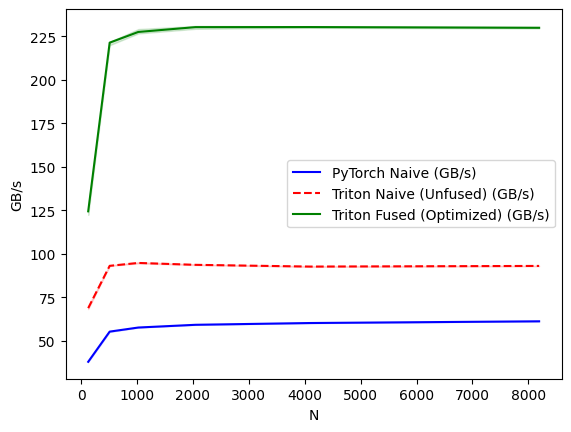

softmax-performance:
        N  PyTorch Naive (GB/s)  Triton Naive (Unfused) (GB/s)  Triton Fused (Optimized) (GB/s)
0   128.0             38.002900                      68.840336                       124.474836
1   512.0             55.351349                      93.157072                       221.405396
2  1024.0             57.702841                      94.812244                       227.555548
3  2048.0             59.275073                      93.727461                       230.329716
4  4096.0             60.290708                      92.729715                       230.367654
5  8192.0             61.277233                      93.097624                       229.950887


In [15]:
@triton.testing.perf_report(
    triton.testing.Benchmark(
            x_names=['N'],
            x_vals=[128, 512, 1024, 2048, 4096, 8192],
            line_arg='provider',
            line_vals=['pytorch', 'triton-naive', 'triton-fused'],
            line_names=['PyTorch Naive', 'Triton Naive (Unfused)', 'Triton Fused (Optimized)'],
            styles=[('blue', '-'), ('red', '--'), ('green', '-')],
            ylabel='GB/s',
            plot_name='softmax-performance',
            args={'M': 4096}
    )
)
def benchmark(M, N, provider):
    x = torch.randn(M, N, device=DEVICE, dtype=torch.float32)
    quantiles = [0.5, 0.2, 0.8]
    if provider == 'pytorch':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: naive_softmax(x), quantiles=quantiles)
    elif provider == 'triton-naive':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: naive_triton_softmax(x), quantiles=quantiles)
    elif provider == 'triton-fused':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: fused_triton_softmax(x), quantiles=quantiles)

    # GB/s = 2 (1 read, 1 write) * M * N * 4 bytes / (ms * 1e-3) / 1e9
    gbps = lambda ms: 2 * M * N * 4 / (ms * 1e-3) / 1e9
    return gbps(ms), gbps(max_ms), gbps(min_ms)

# Run the performance benchmark
benchmark.run(show_plots=True, print_data=True)

### 🔬 Analysis: How Fusion Accelerates Memory Bandwidth

The optimization technique applied in our `fused_triton_softmax` kernel is mathematically classified as **Kernel/Memory Fusion** combined with **Reduction Fusion**:

* **Memory & Register Fusion**: Pointwise operators (`sub`, `exp`, `div`) are combined into a single kernel pass. Data stays in the GPU's register file, cutting DRAM writes and reads to the theoretical minimum.
* **Reduction Fusion**: The horizontal reductions (`tl.max` and `tl.sum`) are computed within the same thread-block lifecycle. This avoids scheduling separate reduction kernels and the subsequent global synchronization overhead.
* **Efficiency Impact**: We collapse 5 sequential kernel dispatches into **1 single kernel execution**, shifting the limit of our operation from global memory bandwidth toward compute capability.

### Comparing Manual Triton Fusion to XLA and `torch.compile` (Inductor)

While writing manual Triton kernels gives you low-level control over hardware registers, memory hierarchies, and warp layouts, modern compilers like **XLA** and **`torch.compile`** (specifically via its default backend, **Inductor**) attempt to automate this fusion process. Here is how they compare across key dimensions:

---

### 1. `torch.compile` (PyTorch Inductor)
Introduced in PyTorch 2.0, `torch.compile` acts as an automatic compiler. Under the hood, the default compiler backend **Inductor** actually generates custom **Triton code** dynamically.

* **How it works**: It traces the PyTorch Python graph, identifies regions of element-wise and reduction operations, and automatically groups (fuses) them. It then generates, compiles, and runs optimized Triton code on the fly.
* **Level of Control**: Fully automated. The user writes standard PyTorch code; the compiler handles the kernel fusion.
* **Performance**: Extremely close to manual Triton. For standard softmax or pointwise-heavy layers, Inductor's auto-generated Triton kernels will perform identically to our hand-written `fused_triton_softmax` without requiring you to manually write a single GPU program.

### 2. XLA Compilation (Accelerated Linear Algebra)
XLA is the compiler that powers **JAX** and **TensorFlow**.

* **How it works**: XLA takes a computation graph and builds "fusion groups." It is highly mature and aggressively merges operations (e.g., fusing element-wise operations, reductions, and even transposes) into single GPU/TPU execute blocks.
* **Backend Generation**: XLA emits low-level CUDA C++ or LLVM IR code directly, rather than intermediate Triton code.
* **Limitation**: While incredibly fast on both GPUs and TPUs, it compiles in a closed ecosystem. If XLA does not support a highly specific, complex memory routing pattern, it can be difficult for a developer to inject custom CUDA/Triton kernels directly into the pipeline without breaking compilation boundaries.

---

### Comparison Summary

| Feature | Manual Triton | `torch.compile` (Inductor) | XLA Compilation (JAX/TF) |
| :--- | :--- | :--- | :--- |
| **Under the Hood** | Custom low-level GPU programming using Triton Python syntax. | Automates graph tracing and dynamically generates Triton code. | Graph compiler that emits low-level native CUDA C++ / LLVM IR. |
| **Development Effort** | High. Must handle pointers, block sizing, masking, and grid layouts. | Low. Just wrap your PyTorch function with `@torch.compile()`. | Low. Wrap code with `@jax.jit` or use native compilation. |
| **Flexibility** | Maximum. You can build highly customized non-standard algorithms. | Medium-High. Relies on compiler patterns but supports custom fallback Triton kernels easily. | Medium. Highly optimized for standard graphs; difficult to inject custom CUDA. |
| **Optimization Strategy** | User-managed memory/register allocation. | Auto-fuses pointwise operations & simple reductions into Triton. | High-level algebraic graph rewriting and fusion pipelines. |

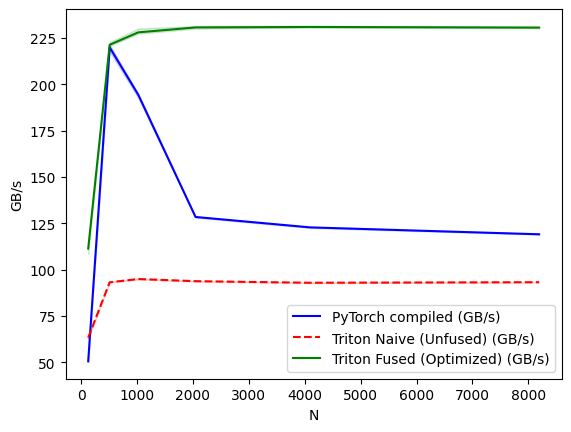

softmax-performance:
        N  PyTorch compiled (GB/s)  Triton Naive (Unfused) (GB/s)  Triton Fused (Optimized) (GB/s)
0   128.0                50.519176                      63.289234                       111.361088
1   512.0               220.011751                      93.173631                       221.405396
2  1024.0               194.360709                      94.941012                       228.100073
3  2048.0               128.439004                      93.786149                       230.760556
4  4096.0               122.830820                      92.941356                       231.014768
5  8192.0               119.098850                      93.221774                       230.671721


In [17]:
compiled = torch.compile(naive_softmax)
@triton.testing.perf_report(
    triton.testing.Benchmark(
            x_names=['N'],
            x_vals=[128, 512, 1024, 2048, 4096, 8192],
            line_arg='provider',
            line_vals=['pytorch', 'triton-naive', 'triton-fused'],
            line_names=['PyTorch compiled', 'Triton Naive (Unfused)', 'Triton Fused (Optimized)'],
            styles=[('blue', '-'), ('red', '--'), ('green', '-')],
            ylabel='GB/s',
            plot_name='softmax-performance',
            args={'M': 4096}
    )
)
def benchmark(M, N, provider):
    x = torch.randn(M, N, device=DEVICE, dtype=torch.float32)
    quantiles = [0.5, 0.2, 0.8]
    if provider == 'pytorch':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: compiled(x), quantiles=quantiles)
    elif provider == 'triton-naive':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: naive_triton_softmax(x), quantiles=quantiles)
    elif provider == 'triton-fused':
        ms, min_ms, max_ms = triton.testing.do_bench(lambda: fused_triton_softmax(x), quantiles=quantiles)

    # GB/s = 2 (1 read, 1 write) * M * N * 4 bytes / (ms * 1e-3) / 1e9
    gbps = lambda ms: 2 * M * N * 4 / (ms * 1e-3) / 1e9
    return gbps(ms), gbps(max_ms), gbps(min_ms)

# Run the performance benchmark
benchmark.run(show_plots=True, print_data=True)

1. The Decision Engine: TorchInductor
When you call torch.compile, PyTorch's compiler backend (TorchInductor) represents your PyTorch operations as a Directed Acyclic Graph (DAG) of mathematical operations. Inductor then categorizes these nodes primarily into two categories:

Pointwise / Element-wise Operations: Operations like addition, subtraction, multiplication, and element-wise functions (such as torch.exp).
Reduction Operations: Operations that collapse dimensions, like torch.sum or torch.max along an axis.
2. The Core Heuristic: Loop Fusion Rules
TorchInductor runs optimization passes on the graph using a set of highly optimized compiler heuristics to decide when fusion is beneficial:

Rule 1: Pointwise with Pointwise
If Node A (e.g., subtract) flows directly into Node B (e.g., exp), they are always fused. There is no mathematical reason not to, as it replaces a slow DRAM write/read with a direct register handoff.

Rule 2: Pointwise with Reduction
If an element-wise operation immediately precedes or follows a reduction, Inductor will try to fuse them. For example, in naive_softmax, the subtraction of the maximum value (x - x_max) and the subsequent exponential are grouped directly with the row-sum reduction inside a single Triton loop.

Rule 3: Compatible Memory Layouts and Grid Dimensions
Inductor looks at the strides (how data is laid out in memory) and loop bounds (shapes). If two operations share the same iteration space (e.g., they both loop over columns in the same row), Inductor fuses them into the same Triton block loop.

3. Why torch.compile Dropped in Performance for Large $N$$N$ in our Benchmark
If you look closely at your benchmark chart, you will see something fascinating: PyTorch compiled matches Triton Fused's performance perfectly up to $N = 512$$N = 512$, but then its performance begins to drop significantly for $N \ge 1024$$N \ge 1024$.

This behavior highlights the limits of automated compiler decisions:

SRAM/Register Limits (Register Spilling): As the column size $N$$N$ gets larger, the compiler-generated Triton kernel needs a larger BLOCK_SIZE to fit the entire row into SRAM. If the automatic compiler allocates too many registers or intermediate variables, it runs out of physical GPU register space. This causes "register spilling," where the GPU starts swapping register data back and forth to slow local memory, tanking the memory bandwidth.
Conservative Tiling: When $N$$N$ becomes too large, torch.compile's heuristics decide that fitting the entire row into a single block is too risky. It falls back to a multi-pass split-reduction strategy (similar to our unfused Triton version) to avoid compile-time failure. On the other hand, our hand-written Triton kernel forced a single-pass fused row-major strategy that remained highly optimized for larger widths.

## 🏁 Summary & Key Takeaways

In this notebook, we investigated the memory bottlenecks of a naive PyTorch Softmax implementation and explored how kernel fusion addresses these limits both manually (via **Triton**) and automatically (via **`torch.compile`**).

### 💡 Key Findings

1. **The DRAM Fetch Bottleneck**
   - **Naive PyTorch**: Suffers from excessive global memory roundtrips ($5MN + 2M$ reads and $3MN + 2M$ writes) because it schedules independent GPU kernels for each intermediate step.
   - **Triton Fused**: Achieves the mathematically optimal access pattern ($MN$ reads and $MN$ writes) by keeping intermediate tensors entirely in on-chip registers and SRAM.

2. **Performance Comparison**
   - **Triton Fused (Optimized)** achieves the highest throughput, sustaining **~230 GB/s** across all tested column dimensions $N$.
   - **Triton Naive (Unfused)** isolates the framework overhead, proving that even custom Triton kernels suffer significantly when forced to make unnecessary roundtrips to DRAM (~93 GB/s).
   - **`torch.compile` (Inductor)** matches Triton Fused's peak performance at smaller row sizes ($N \le 512$). However, for larger row sizes ($N \ge 1024$), compiler heuristics conservatively fall back to a split-reduction strategy to avoid register spilling, dropping its throughput to ~120 GB/s.

3. **When to Compile vs. When to Write Custom Triton**
   - **Use `torch.compile` first**: It is highly automated, elegant, and matches hand-crafted speeds for most standard pointwise and medium-scale reduction patterns.
   - **Write manual Triton kernels** when working with highly non-standard layouts, massive row sizes that require customized tiling/reduction strategies, or when you need absolute control over hardware resources to maximize GPU utilization.